# **Single Image Augmentation Experiment**
Using modified Keras (*ImageDataGenerator* does not random transform)

## **Import Libraries**

Import libraries

In [ ]:
import os
import numpy as np
from zipfile import ZipFile
import matplotlib.pyplot as plt

Import modified Keras

In [ ]:
from keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, save_img

## **Display Single Image Augmentation**

Display single augmented image

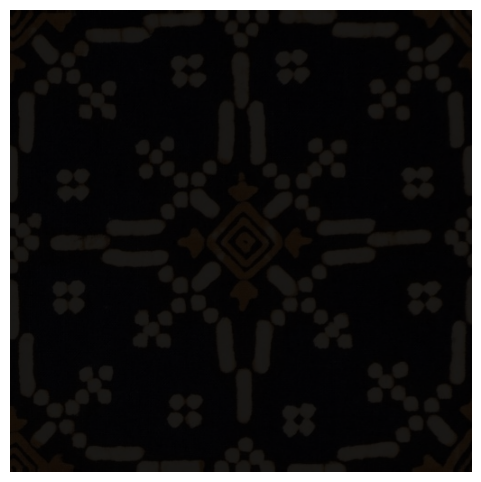

In [ ]:
def process_and_display_image():
    # Load the image
    image_path = 'input_image.jpg'
    img = load_img(image_path)
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Create an ImageDataGenerator with rotation
    datagen = ImageDataGenerator(brightness_range=(0.1, 0.1))

    # Prepare the iterator
    iterator = datagen.flow(img_array, batch_size=1)

    # Generate augmented image
    augmented_image = iterator.next()[0].astype('uint8')

    # Display the image
    plt.figure(figsize=(6, 6))
    plt.imshow(augmented_image)
    plt.axis('off')
    plt.show()

process_and_display_image()

## **Single Image Multiple Augmentation**

Function: save augmented image

In [ ]:
def save_augmented_image(image, directory, file_name):
    if not os.path.exists(directory):
        os.makedirs(directory)
    save_path = os.path.join(directory, file_name)
    save_img(save_path, image)
    return save_path

Function: Augment Image

In [ ]:
def augment_image(img_path):
    # Load the image
    img = load_img(img_path)
    img = img_to_array(img)
    img = np.expand_dims(img, axis=0)

    # Define ranges for augmentation parameters
    params = {
        'rotation_range': (30, 180, 30),
        'width_shift_range': (0.2, 0.8, 0.2),
        'height_shift_range': (0.2, 0.8, 0.2),
        'zoom_range': (0.2, 0.8, 0.2),
        # 'brightness_range': (0.2, 0.8, 0.2)
    }

    # Prepare to save files
    root_dir = 'augmented_images'
    if not os.path.exists(root_dir):
        os.makedirs(root_dir)

    # Loop over each parameter and its range
    for param, (min_val, max_val, step) in params.items():
        current_dir = os.path.join(root_dir, param)
        if not os.path.exists(current_dir):
            os.makedirs(current_dir)

        for value in np.arange(min_val, max_val + step, step):
            ### BRIGHTNESS_RANGE NOT WORKING
            # if param == 'brightness_range':
            #     generator = ImageDataGenerator(brightness_range=(value, value))
            # else:
            generator = ImageDataGenerator(**{param: value,
                                              'fill_mode':'nearest'})

            # Generate augmented images
            images_flow = generator.flow(img, batch_size=1)
            batch = next(images_flow)
            augmented_image = batch[0].astype('uint8')

            # Save the augmented image
            file_name = f"{param}_{value:.1f}.jpg"
            save_augmented_image(augmented_image, current_dir, file_name)

Execute `augment_image()`

In [ ]:
augment_image('input_image.jpg')

## **Single Image *BRIGHTNESS* Augmentation**

Function: augment brightness of single image

In [ ]:
def process_and_save_image(image_path, save_dir='augmented_images'):
    brightness_range = (0.2, 0.8, 0.2)
    brightness_values = np.arange(brightness_range[0], brightness_range[1] + brightness_range[2], brightness_range[2])

    img = load_img(image_path)
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    save_subdir = os.path.join(save_dir, 'brightness_range')
    os.makedirs(save_subdir, exist_ok=True)

    # Iterate through each brightness value and generate augmented images
    for brightness in brightness_values:
        # Create an ImageDataGenerator with the specified brightness range
        datagen = ImageDataGenerator(brightness_range=(brightness, brightness),
                                     fill_mode='nearest')

        # Prepare the iterator
        iterator = datagen.flow(img_array, batch_size=1)

        # Generate augmented image
        augmented_image = iterator.next()[0].astype('uint8')

        # Create the file name and save the image
        file_name = f'brightness_range_{brightness:.1f}.jpg'
        file_path = os.path.join(save_subdir, file_name)
        plt.imsave(file_path, augmented_image)
        print(f'Saved: {file_path}')

Save the ***brightness***-augmented images

In [ ]:
process_and_save_image('input_image.jpg')

Saved: augmented_images/brightness_range/brightness_range_0.2.jpg
Saved: augmented_images/brightness_range/brightness_range_0.4.jpg
Saved: augmented_images/brightness_range/brightness_range_0.6.jpg
Saved: augmented_images/brightness_range/brightness_range_0.8.jpg


## **Utilities**

Save augmented images as `Zip`

In [ ]:
# Zip all the directories
def zip_augmented_dir(root_dir):
    zip_path = os.path.join(os.getcwd(), 'keras_idg_augmented_images.zip')
    with ZipFile(zip_path, 'w') as zipf:
        for folder_name in os.listdir(root_dir):
            folder_path = os.path.join(root_dir, folder_name)
            if os.path.isdir(folder_path):
                for filename in os.listdir(folder_path):
                    file_path = os.path.join(folder_path, filename)
                    zipf.write(file_path, os.path.relpath(file_path, root_dir))

    print(f"All images have been saved and zipped in {zip_path}")

zip_augmented_dir('augmented_images')

All images have been saved and zipped in /content/keras_idg_augmented_images.zip


Delete directory on `parameter`

In [ ]:
import shutil

def delete_directory(dir_path):
    if os.path.exists(dir_path) and os.path.isdir(dir_path):
        shutil.rmtree(dir_path)
        print(f"Directory '{dir_path}' and all its contents have been deleted.")
    else:
        print(f"Directory '{dir_path}' does not exist or is not a directory.")

delete_directory('augmented_images')

Directory 'augmented_images' and all its contents have been deleted.
